> **Original exploratory notebook, kept with its outputs for reference** (Spanish, run in Google Colab). It is superseded by the `luad_survival` package, which repeats the same analysis at **patient level** and fixes several issues found later: the cohort tables and Cox models count *rows*, not patients (the survival file has 645 rows for 507 patients, because it also holds normal-tissue and recurrence samples, and the merge repeats rows: the Cox model reports 878 observations); an unsigned signature score; a second log transform on already log-scaled values; and feature filtering on all patients. The interpretation texts near the end ("coherencia global") are stronger than the held-out results support; see the README.

#**LUAD**

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
clinical = "/content/drive/MyDrive/Mis proyectos/LUAD/TCGA-LUAD.clinical.tsv.gz"
star = "/content/drive/MyDrive/Mis proyectos/LUAD/TCGA-LUAD.star_tpm.tsv.gz"
survival = "/content/drive/MyDrive/Mis proyectos/LUAD/TCGA-LUAD.survival.tsv.gz"

In [3]:
import pandas as pd
import numpy as np

expr = pd.read_csv(
    star,
    sep="\t",
    index_col=0
)

expr.shape


(60660, 589)

In [4]:
surv = pd.read_csv(
    survival,
    sep="\t"
)

surv.columns

Index(['sample', 'OS.time', 'OS', '_PATIENT'], dtype='object')

In [5]:
pheno = pd.read_csv(
    clinical,
    sep="\t"
)

pheno.columns

Index(['sample', 'id', 'disease_type', 'case_id', 'submitter_id',
       'primary_site', 'cigarettes_per_day.exposures',
       'alcohol_history.exposures', 'years_smoked.exposures',
       'pack_years_smoked.exposures', 'race.demographic', 'gender.demographic',
       'ethnicity.demographic', 'vital_status.demographic',
       'age_at_index.demographic', 'days_to_birth.demographic',
       'year_of_birth.demographic', 'year_of_death.demographic',
       'primary_site.project', 'project_id.project', 'disease_type.project',
       'name.project', 'name.program.project',
       'tissue_source_site_id.tissue_source_site', 'code.tissue_source_site',
       'name.tissue_source_site', 'project.tissue_source_site',
       'bcr_id.tissue_source_site', 'days_to_death.demographic',
       'entity_submitter_id.annotations', 'notes.annotations',
       'submitter_id.annotations', 'classification.annotations',
       'entity_id.annotations', 'created_datetime.annotations',
       'annotation_id.ann

In [6]:
expr.columns = expr.columns.str.slice(0, 12)
surv["sample_id"] = surv["sample"].str.slice(0, 12)
pheno["sample_id"] = pheno["sample"].str.slice(0, 12)

In [7]:
common_ids = (
    set(expr.columns)
    & set(surv["sample_id"])
    & set(pheno["sample_id"])
)

len(common_ids)

504

In [8]:
expr_filt = expr[list(common_ids)]
surv_filt = surv[surv["sample_id"].isin(common_ids)]
pheno_filt = pheno[pheno["sample_id"].isin(common_ids)]

#**EDA**

In [9]:
print("Expresión:", expr_filt.shape)
print("Survival:", surv_filt.shape)
print("Phenotype:", pheno_filt.shape)

Expresión: (60660, 576)
Survival: (642, 5)
Phenotype: (642, 90)


In [10]:
surv_filt["OS"].value_counts()

,count
OS,
0,401
1,241


In [11]:
surv_filt["OS.time"].describe()

,OS.time
count,642.000000
mean,929.102804
std,884.319287
min,4.000000
25%,430.250000
50%,701.500000
75%,1166.000000
max,7248.000000


In [12]:
clinical_cols = [
    "sample_id",
    "OS.time",
    "OS",
    "age_at_diagnosis.diagnoses",
    "gender.demographic",
    "ajcc_pathologic_stage.diagnoses"
]

clin = (
    surv_filt.merge(pheno_filt, on="sample_id")
    [clinical_cols]
)

In [13]:
clin.head()

,sample_id,OS.time,OS,age_at_diagnosis.diagnoses,gender.demographic,ajcc_pathologic_stage.diagnoses
0,TCGA-NJ-A4YI,4.0,1,31867.0,female,Stage IIIA
1,TCGA-55-8506,11.0,0,22850.0,female,Stage IIB
2,TCGA-NJ-A55O,13.0,0,20628.0,female,Stage IIA
3,TCGA-35-3615,14.0,0,21076.0,male,Stage IB
4,TCGA-NJ-A55A,15.0,0,28022.0,female,Stage IB


In [14]:
clin.isna().sum()

,0
sample_id,0
OS.time,0
OS,0
age_at_diagnosis.diagnoses,49
gender.demographic,0
ajcc_pathologic_stage.diagnoses,14


In [15]:
#Este código elimina genes que prácticamente no se expresan, dejando solo aquellos con señal biológica real, mejorando la calidad del análisis posterior.
gene_means = expr_filt.mean(axis=1)
expr_filtered = expr_filt.loc[gene_means > 1]
expr_filtered.shape

(17993, 576)

In [16]:
clin["OS"].value_counts()

,count
OS,
0,577
1,363


In [17]:
clin["OS.time"].describe()

,OS.time
count,940.000000
mean,946.934043
std,863.312364
min,4.000000
25%,444.000000
50%,740.500000
75%,1194.750000
max,7248.000000


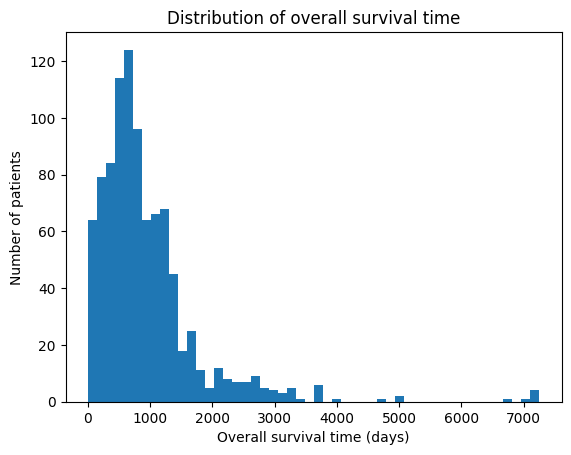

In [18]:
import matplotlib.pyplot as plt

plt.hist(clin["OS.time"], bins=50)
plt.xlabel("Overall survival time (days)")
plt.ylabel("Number of patients")
plt.title("Distribution of overall survival time")
plt.show()

In [19]:
clin["age_at_diagnosis.diagnoses"].describe()

,age_at_diagnosis.diagnoses
count,891.000000
mean,23885.875421
std,3602.954982
min,12179.000000
25%,21766.000000
50%,24014.000000
75%,26442.000000
max,32432.000000


In [20]:
clin["age_years"] = clin["age_at_diagnosis.diagnoses"] / 365.25
clin["age_years"].describe()

,age_years
count,891.000000
mean,65.395963
std,9.864353
min,33.344285
25%,59.592060
50%,65.746749
75%,72.394251
max,88.793977


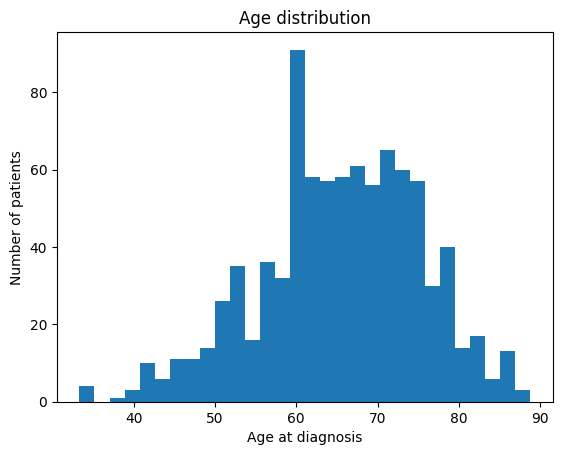

In [21]:
plt.hist(clin["age_years"], bins=30)
plt.xlabel("Age at diagnosis")
plt.ylabel("Number of patients")
plt.title("Age distribution")
plt.show()

In [22]:
clin[["age_years", "OS.time"]].corr()

,age_years,OS.time
age_years,1.000000,-0.086528
OS.time,-0.086528,1.000000


In [23]:
clin["age_group"] = pd.qcut(
    clin["age_at_diagnosis.diagnoses"],
    q=4,
    labels=["Q1 (young)", "Q2", "Q3", "Q4 (old)"]
)
clin["age_group"].value_counts()


,count
age_group,
Q1 (young),229
Q4 (old),223
Q3,220
Q2,219


In [24]:
clin["gender.demographic"].value_counts()

,count
gender.demographic,
female,516
male,424


In [25]:
clin["ajcc_pathologic_stage.diagnoses"].value_counts(dropna=False)

,count
ajcc_pathologic_stage.diagnoses,
Stage IB,271
Stage IA,239
Stage IIIA,136
Stage IIB,130
Stage IIA,83
Stage IV,48
NaN,14
Stage IIIB,13
Stage I,5


In [26]:
def simplify_stage(stage):
    if pd.isna(stage):
        return np.nan

    stage = stage.strip()

    if stage.startswith("Stage III") or stage.startswith("Stage IV"):
        return "Advanced"

    if stage.startswith("Stage I") or stage.startswith("Stage II"):
        return "Early"

    return np.nan


clin["stage_group"] = clin["ajcc_pathologic_stage.diagnoses"].apply(simplify_stage)
clin["stage_group"].value_counts(dropna=False)

,count
stage_group,
Early,729
Advanced,197
NaN,14


In [27]:
clin.groupby("stage_group")["OS.time"].median()

,OS.time
stage_group,
Advanced,578.0
Early,808.0


In [28]:
clinical_summary = clin.groupby("stage_group").agg(
    n_patients=("sample_id", "count"),
    median_age=("age_years", "median"),
    deaths=("OS", "sum"),
    median_OS=("OS.time", "median")
)

clinical_summary

,n_patients,median_age,deaths,median_OS
stage_group,,,,
Advanced,197,66.91718,112,578.0
Early,729,65.59206,246,808.0


In [29]:
stage_col = "ajcc_pathologic_stage.diagnoses"

summary_stage = (
    clin
    .dropna(subset=[stage_col])
    .groupby([ "stage_group", stage_col ])
    .agg(
        n_patients=("sample_id", "count"),
        events=("OS", "sum"),
        median_OS=("OS.time", "median")
    )
)

summary_stage["event_rate_pct"] = (
    summary_stage["events"] / summary_stage["n_patients"] * 100
).round(1)

In [30]:
stage_order = [
    "Stage IA", "Stage IB",
    "Stage IIA", "Stage IIB",
    "Stage IIIA", "Stage IIIB",
    "Stage IV"
]

summary_stage = summary_stage.reset_index()

summary_stage[stage_col] = pd.Categorical(
    summary_stage[stage_col],
    categories=stage_order,
    ordered=True
)

summary_stage = (
    summary_stage
    .sort_values(["stage_group", stage_col])
    .set_index(["stage_group", stage_col])
    [["n_patients", "events", "event_rate_pct", "median_OS"]]
)


In [31]:
summary_stage

n_patients  events  \
stage_group ajcc_pathologic_stage.diagnoses                       
Advanced    Stage IIIA                              136      78   
            Stage IIIB                               13       9   
            Stage IV                                 48      25   
Early       Stage IA                                239      46   
            Stage IB                                271      94   
            Stage IIA                                83      42   
            Stage IIB                               130      62   
            nan                                       5       1   
            nan                                       1       1   

                                             event_rate_pct  median_OS  
stage_group ajcc_pathologic_stage.diagnoses                             
Advanced    Stage IIIA                                 57.4      473.0  
            Stage IIIB                                 69.2      651.0  
            Stage IV                                   52.1      578.0  
Early       Stage IA                                   19.2      824.0  
            Stage IB                                   34.7      808.0  
            Stage IIA                                  50.6      599.0  
            Stage IIB                                  47.7      865.0  
            nan                                        20.0      578.0  
            nan                                       100.0      677.0

In [32]:
!pip install lifelines
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test

kmf = KaplanMeierFitter()

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 349.3/349.3 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.3/117.3 kB 10.1 MB/s eta 0:00:00
  Created wheel for autograd-gamma: filename=autograd_gamma-0.5.0-py3-none-any.whl size=4030 sha256=1bfe9450b63306b0a0a65b6f1599d1e487e94423ddac90f175829ed1a0e74181
  Stored in directory: /root/.cache/pip/wheels/50/37/21/0a719b9d89c635e89ff24bd93b862882ad675279552013b2fb
Successfully built autograd-gamma


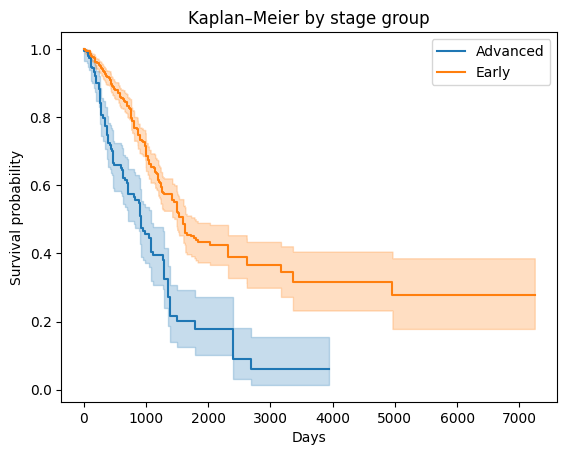

In [33]:
for group in clin["stage_group"].dropna().unique():
    ix = clin["stage_group"] == group
    kmf.fit(
        clin.loc[ix, "OS.time"],
        event_observed=clin.loc[ix, "OS"],
        label=group
    )
    kmf.plot_survival_function()

plt.title("Kaplan–Meier by stage group")
plt.xlabel("Days")
plt.ylabel("Survival probability")
plt.show()

El gráfico de Kaplan–Meier estratificado por grupo de estadio patológico muestra una separación clara y sostenida entre las curvas de supervivencia correspondientes a pacientes con enfermedad en estadio temprano (Early) y avanzado (Advanced) a lo largo de todo el período de seguimiento. Desde los primeros meses posteriores al diagnóstico se observa un descenso más pronunciado de la probabilidad de supervivencia en el grupo Advanced, lo que indica una mayor tasa de eventos tempranos en comparación con el grupo Early. Esta divergencia temprana sugiere que el estadio patológico al momento del diagnóstico es un determinante fuerte del pronóstico en adenocarcinoma de pulmón, incluso antes de considerar otras covariables clínicas o moleculares.

A medida que transcurre el tiempo de seguimiento, la distancia entre ambas curvas se mantiene e incluso se amplía, evidenciando diferencias sustanciales en la dinámica de supervivencia a largo plazo. Mientras que los pacientes en estadio temprano presentan una disminución más gradual de la supervivencia, con una proporción considerable de individuos que permanecen vivos durante varios años, el grupo Advanced alcanza probabilidades de supervivencia marcadamente bajas en un intervalo temporal más corto. Este patrón es consistente con la biología clínica de la enfermedad, donde los estadios avanzados suelen asociarse a mayor carga tumoral, presencia de enfermedad locorregional o metastásica y, en consecuencia, menor respuesta terapéutica y mayor riesgo de mortalidad.

Las bandas de confianza alrededor de las curvas reflejan la incertidumbre asociada a las estimaciones de supervivencia y se ensanchan progresivamente en tiempos de seguimiento más prolongados, particularmente en el grupo Advanced. Este comportamiento es esperable debido a la reducción del número de pacientes en riesgo a medida que ocurren eventos y censuras. No obstante, incluso considerando esta incertidumbre, la separación entre ambos grupos permanece claramente definida, lo que refuerza la robustez de la asociación entre estadio patológico y supervivencia global.

En conjunto, este análisis confirma que la estratificación por estadio patológico discrimina eficazmente subpoblaciones con pronósticos claramente diferenciados en la cohorte TCGA-LUAD. La marcada diferencia en las curvas de Kaplan–Meier valida el estadio como un “ground truth” clínico del riesgo de mortalidad y proporciona un marco de referencia sólido para análisis posteriores. En particular, estos resultados justifican la integración de variables transcriptómicas con el objetivo de identificar firmas moleculares que capturen, y potencialmente refinen, el riesgo pronóstico más allá de lo explicado por el estadio clínico convencional.


In [34]:
cox_df = clin[[
    "OS.time",
    "OS",
    "age_years",
    "stage_group",
    "gender.demographic"
]].dropna()

cox_df["stage_group"] = (cox_df["stage_group"] == "Advanced").astype(int)
cox_df["gender_female"] = (cox_df["gender.demographic"] == "female").astype(int)

cox_df = cox_df.drop(columns=["gender.demographic"])

from lifelines import CoxPHFitter

cph = CoxPHFitter()
cph.fit(cox_df, duration_col="OS.time", event_col="OS")
cph.print_summary()

<lifelines.CoxPHFitter: fitted with 878 total observations, 544 right-censored observations>
             duration col = 'OS.time'
                event col = 'OS'
      baseline estimation = breslow
   number of observations = 878
number of events observed = 334
   partial log-likelihood = -1940.21
         time fit was run = 2025-12-22 14:41:25 UTC

---
               coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                      
age_years      0.01      1.01      0.01           -0.00            0.02                1.00                1.02
stage_group    0.88      2.41      0.12            0.65            1.11                1.91                3.03
gender_female  0.11      1.11      0.11           -0.11            0.33                0.89                1.39

               cmp to    z      p  -log2(p)
covariate                                  
age_years        0.00 1.59   0.11      3.16
stage_group      0.00 7.47 <0.005     43.55
gender_female    0.00 0.96   0.34      1.58
---
Concordance = 0.62
Partial AIC = 3886.43
log-likelihood ratio test = 53.04 on 3 df
-log2(p) of ll-ratio test = 35.69

El modelo de riesgos proporcionales de Cox ajustado sobre la cohorte TCGA-LUAD permite cuantificar de manera multivariada el efecto de variables clínicas fundamentales —edad al diagnóstico, estadio patológico y sexo— sobre la supervivencia global. El análisis se realizó sobre 878 observaciones, de las cuales se registraron 334 eventos, lo que proporciona una base adecuada para la estimación estable de los coeficientes del modelo. El test global de razón de verosimilitud es altamente significativo, lo que indica que el conjunto de covariables incluidas mejora de forma sustancial el ajuste del modelo en comparación con un modelo nulo sin predictores.

El estadio patológico emerge como el principal determinante pronóstico en el modelo. La variable binaria que compara enfermedad avanzada frente a temprana presenta un coeficiente positivo elevado, correspondiente a un hazard ratio de aproximadamente 2.4, con un intervalo de confianza del 95% que no incluye la unidad y un valor de p extremadamente bajo. Esto implica que, manteniendo constantes la edad y el sexo, los pacientes diagnosticados en estadios avanzados presentan más del doble de riesgo instantáneo de muerte en comparación con aquellos en estadios tempranos. Este resultado es coherente con la evidencia clínica y valida el estadio como un fuerte factor pronóstico independiente en el adenocarcinoma de pulmón.

#**EDA Transcriptomico**

/tmp/ipython-input-4282628890.py:29: FutureWarning: DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.
  expr_unique = expr_filtered.groupby(expr_filtered.columns, axis=1).mean()


Explained variance ratio (PC1..PC10): [0.1175 0.0832 0.0633 0.0453 0.039  0.0315 0.0263 0.0209 0.02   0.0174]
Cumulative explained variance (PC1+PC2): 0.2007


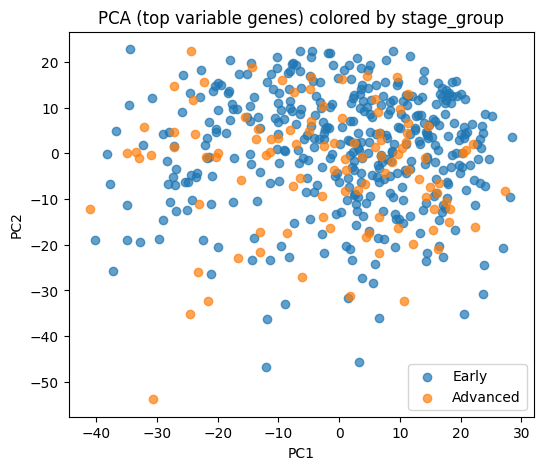

In [35]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# ---------------------------
# 0) Deduplicación clínica robusta (NO volver a redefinir clin_1 después)
# ---------------------------
key_cols = ["OS.time", "OS", "age_years", "stage_group"]
missing = [c for c in key_cols if c not in clin.columns]
if missing:
    raise ValueError(f"Faltan columnas en clin: {missing}")

clin_tmp = clin.copy()
clin_tmp["na_key"] = clin_tmp[key_cols].isna().sum(axis=1)

clin_1 = (
    clin_tmp
    .sort_values(by=["sample_id", "na_key", "OS.time"], ascending=[True, True, False])
    .drop_duplicates(subset=["sample_id"], keep="first")
    .drop(columns=["na_key"])
)

clin_idx = clin_1.set_index("sample_id")

## ---------------------------
# 1) Expresión única + genes variables + X (log1p)
# ---------------------------
expr_unique = expr_filtered.groupby(expr_filtered.columns, axis=1).mean()
gene_vars = expr_unique.var(axis=1)
top_var_genes = gene_vars.sort_values(ascending=False).head(2000).index

X = np.log1p(expr_unique.loc[top_var_genes].T)

# ---------------------------
# 2) PCA (solo para explorar estructura; usa stage_group si está)
# ---------------------------
common_ids = X.index.intersection(clin_idx.index)
X = X.loc[common_ids]
stage = clin_idx.reindex(common_ids)["stage_group"]

mask = stage.notna()
X_pca = X.loc[mask]
stage_pca = stage.loc[mask]

X_scaled = StandardScaler().fit_transform(X_pca)
pca = PCA(n_components=10, random_state=42)
pcs = pca.fit_transform(X_scaled)

evr = pca.explained_variance_ratio_
print("Explained variance ratio (PC1..PC10):", np.round(evr, 4))
print("Cumulative explained variance (PC1+PC2):", round(evr[:2].sum(), 4))

pca_df = pd.DataFrame(pcs[:, :3], index=X_pca.index, columns=["PC1", "PC2", "PC3"])
pca_df["stage_group"] = stage_pca.values

plt.figure(figsize=(6,5))
for g in ["Early", "Advanced"]:
    m = pca_df["stage_group"] == g
    plt.scatter(pca_df.loc[m, "PC1"], pca_df.loc[m, "PC2"], alpha=0.7, label=g)
plt.title("PCA (top variable genes) colored by stage_group")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend()
plt.show()

In [36]:
# 9) Medida simple de "señal clínica" en PCA:
# diferencia de medias en PC1/PC2 entre Early vs Advanced (tamaño de efecto de Cohen d)
def cohens_d(a, b):
    a = np.asarray(a); b = np.asarray(b)
    na, nb = len(a), len(b)
    sa, sb = a.std(ddof=1), b.std(ddof=1)
    sp = np.sqrt(((na-1)*sa**2 + (nb-1)*sb**2) / (na+nb-2))
    return (a.mean() - b.mean()) / sp

early = pca_df[pca_df["stage_group"] == "Early"]
adv   = pca_df[pca_df["stage_group"] == "Advanced"]

d_pc1 = cohens_d(early["PC1"], adv["PC1"])
d_pc2 = cohens_d(early["PC2"], adv["PC2"])

print("Cohen's d (Early - Advanced):")
print("PC1:", round(d_pc1, 3))
print("PC2:", round(d_pc2, 3))

# Interpretación rápida:
# |d| ~ 0.2 pequeño, ~0.5 moderado, ~0.8 grande

Cohen's d (Early - Advanced):
PC1: 0.217
PC2: 0.332


In [37]:
# ---------------------------
# 3) Alinear clínica con X (para supervivencia)
# ---------------------------
clin_X = clin_idx.reindex(X.index)
print("NA en outcome:", clin_X[["OS.time", "OS"]].isna().sum())

base = clin_X[["OS.time", "OS", "age_years", "stage_group"]].dropna()
X_base = X.loc[base.index]

NA en outcome: OS.time    0
OS         0
dtype: int64


In [39]:
from sklearn.model_selection import train_test_split
# ---------------------------
# 4) Train/Test split + screening en TRAIN
# ---------------------------
train_ids, test_ids = train_test_split(
    base.index,
    test_size=0.30,
    random_state=42,
    stratify=base["OS"]
)

X_train = X_base.loc[train_ids]
X_test  = X_base.loc[test_ids]

clin_train = base.loc[train_ids].copy()
clin_test  = base.loc[test_ids].copy()

results = []
for gene in X_train.columns:
    df = pd.DataFrame({
        "OS.time": clin_train["OS.time"],
        "OS": clin_train["OS"],
        "gene": X_train[gene]
    }).dropna()

    if df["gene"].var() == 0:
        continue

    cph = CoxPHFitter()
    cph.fit(df, duration_col="OS.time", event_col="OS")

    results.append({
        "gene": gene,
        "HR": float(np.exp(cph.params_["gene"])),
        "p": float(cph.summary.loc["gene", "p"])
    })

res_train = pd.DataFrame(results).sort_values("p").reset_index(drop=True)
display(res_train.head(10))

,gene,HR,p
0,ENSG00000235098.8,0.283595,0.000009
1,ENSG00000189377.9,0.297783,0.000047
2,ENSG00000134013.16,4.739155,0.000074
3,ENSG00000205420.11,1.698760,0.000094
4,ENSG00000128591.16,2.620428,0.000114
5,ENSG00000176842.15,0.452229,0.000147
6,ENSG00000177508.12,0.303872,0.000197
7,ENSG00000163364.10,2.138199,0.000281
8,ENSG00000107984.10,1.726875,0.000297
9,ENSG00000156738.18,0.505216,0.000381


In [40]:
# ---------------------------
# 5) Firma (top 15 genes TRAIN) + umbral TRAIN
# ---------------------------
signature_genes = res_train.head(15)["gene"].tolist()

clin_train["signature_score"] = X_train[signature_genes].mean(axis=1)
clin_test["signature_score"]  = X_test[signature_genes].mean(axis=1)

threshold = clin_train["signature_score"].median()
clin_test["signature_group"] = np.where(clin_test["signature_score"] >= threshold, "High risk", "Low risk")

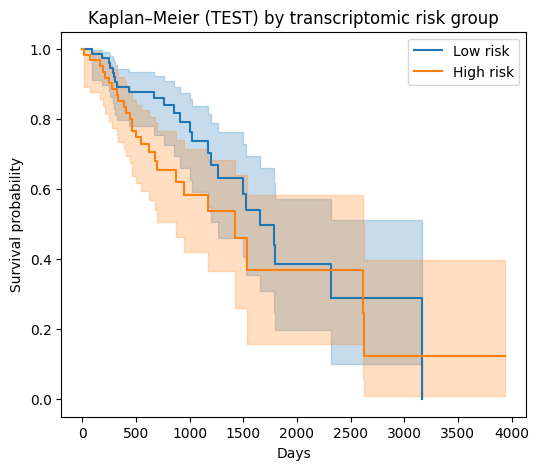

In [41]:
# ---------------------------
# 6) KM en TEST
# ---------------------------
kmf = KaplanMeierFitter()
plt.figure(figsize=(6,5))
for g in ["Low risk", "High risk"]:
    ix = clin_test["signature_group"] == g
    kmf.fit(clin_test.loc[ix, "OS.time"], clin_test.loc[ix, "OS"], label=g)
    kmf.plot_survival_function()
plt.title("Kaplan–Meier (TEST) by transcriptomic risk group")
plt.xlabel("Days")
plt.ylabel("Survival probability")
plt.show()

In [42]:
# ---------------------------
# 7) Cox multivariado en TEST
# ---------------------------
cox_test = clin_test[["OS.time", "OS", "age_years", "stage_group", "signature_score"]].dropna().copy()
cox_test["stage_group"] = (cox_test["stage_group"] == "Advanced").astype(int)

cph_test = CoxPHFitter()
cph_test.fit(cox_test, duration_col="OS.time", event_col="OS")
cph_test.print_summary()

<lifelines.CoxPHFitter: fitted with 143 total observations, 92 right-censored observations>
             duration col = 'OS.time'
                event col = 'OS'
      baseline estimation = breslow
   number of observations = 143
number of events observed = 51
   partial log-likelihood = -201.14
         time fit was run = 2025-12-22 14:46:26 UTC

---
                 coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                        
age_years       -0.01      0.99      0.02           -0.04            0.02                0.96                1.02
stage_group      0.34      1.41      0.33           -0.31            0.99                0.73                2.70
signature_score  2.19      8.95      1.11            0.02            4.37                1.02               78.80

                 cmp to     z    p  -log2(p)
covariate                                   
age_years          0.00 -0.60 0.55      0.86
stage_group        0.00  1.02 0.31      1.71
signature_score    0.00  1.97 0.05      4.37
---
Concordance = 0.65
Partial AIC = 408.28
log-likelihood ratio test = 5.66 on 3 df
-log2(p) of ll-ratio test = 2.95

#**Interpretación de la firma**

In [43]:
import numpy as np
import pandas as pd

# Asegurar que res_train tenga gene, HR, p
res_train_small = res_train[["gene", "HR", "p"]].copy()
res_train_small["logHR"] = np.log(res_train_small["HR"])

# Genes de firma con dirección
sig_df = res_train_small.set_index("gene").loc[signature_genes].reset_index()

risk_genes = sig_df.loc[sig_df["HR"] > 1, "gene"].tolist()
protective_genes = sig_df.loc[sig_df["HR"] < 1, "gene"].tolist()

print("Firma total:", len(signature_genes))
print("Riesgo (HR>1):", len(risk_genes))
print("Protectores (HR<1):", len(protective_genes))

display(sig_df.sort_values("p"))

Firma total: 15
Riesgo (HR>1): 7
Protectores (HR<1): 8


,gene,HR,p,logHR
0,ENSG00000235098.8,0.283595,0.000009,-1.260208
1,ENSG00000189377.9,0.297783,0.000047,-1.211391
2,ENSG00000134013.16,4.739155,0.000074,1.555859
3,ENSG00000205420.11,1.698760,0.000094,0.529899
4,ENSG00000128591.16,2.620428,0.000114,0.963337
5,ENSG00000176842.15,0.452229,0.000147,-0.793566
6,ENSG00000177508.12,0.303872,0.000197,-1.191148
7,ENSG00000163364.10,2.138199,0.000281,0.759964
8,ENSG00000107984.10,1.726875,0.000297,0.546314
9,ENSG00000156738.18,0.505216,0.000381,-0.682768


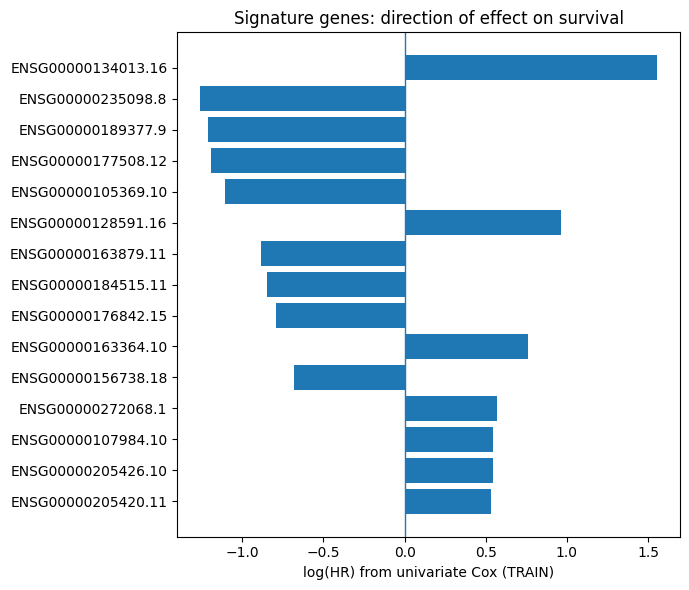

In [44]:
import matplotlib.pyplot as plt

sig_df_plot = sig_df.copy()
sig_df_plot["direction"] = np.where(sig_df_plot["HR"] > 1, "Risk-associated", "Protective")

# ordenar por |logHR|
sig_df_plot["abs_logHR"] = sig_df_plot["logHR"].abs()
sig_df_plot = sig_df_plot.sort_values("abs_logHR", ascending=True)

plt.figure(figsize=(7,6))
plt.barh(sig_df_plot["gene"], sig_df_plot["logHR"])
plt.axvline(0, linewidth=1)
plt.xlabel("log(HR) from univariate Cox (TRAIN)")
plt.title("Signature genes: direction of effect on survival")
plt.tight_layout()
plt.show()

In [45]:
rank_df = res_train_small.dropna().copy()
rank_df = rank_df[rank_df["p"] > 0]  # por seguridad
rank_df["score"] = np.sign(rank_df["logHR"]) * (-np.log10(rank_df["p"]))

# (opcional) cap para evitar outliers extremos por p muy chica
rank_df["score"] = rank_df["score"].clip(lower=-50, upper=50)

# Orden descendente: arriba genes de riesgo fuerte, abajo protectores fuertes
rank_df = rank_df.sort_values("score", ascending=False)

# Formato típico para gseapy: dos columnas [gene, score]
rnk = rank_df[["gene", "score"]]

print("Ranking genes:", rnk.shape)
display(rnk.head(10))
display(rnk.tail(10))

Ranking genes: (2000, 2)


,gene,score
2,ENSG00000134013.16,4.131749
3,ENSG00000205420.11,4.026273
4,ENSG00000128591.16,3.943491
7,ENSG00000163364.10,3.551850
8,ENSG00000107984.10,3.527761
12,ENSG00000272068.1,3.382182
14,ENSG00000205426.10,3.249776
15,ENSG00000171951.5,3.231724
18,ENSG00000079112.10,3.100186
20,ENSG00000123485.12,3.056814


,gene,score
17,ENSG00000170561.13,-3.116132
16,ENSG00000116299.17,-3.202949
13,ENSG00000163879.11,-3.258120
11,ENSG00000105369.10,-3.390029
10,ENSG00000184515.11,-3.416609
9,ENSG00000156738.18,-3.419541
6,ENSG00000177508.12,-3.704659
5,ENSG00000176842.15,-3.831901
1,ENSG00000189377.9,-4.323844
0,ENSG00000235098.8,-5.067139


In [47]:
!pip -q install mygene

import re
import pandas as pd
import numpy as np
import mygene

def strip_ensembl_version(x: str) -> str:
    # ENSG00000123456.12 -> ENSG00000123456
    return re.sub(r"\.\d+$", "", str(x))

# 1) Preparar listado de Ensembl sin versión desde tu ranking
ens = rnk["gene"].astype(str).map(strip_ensembl_version).unique().tolist()

mg = mygene.MyGeneInfo()

# 2) Query masivo (Human)
q = mg.querymany(
    ens,
    scopes="ensembl.gene",
    fields="symbol",
    species="human",
    as_dataframe=True
)

# 3) Construir mapa ENSG -> SYMBOL
# q index = query (ENSG), columna 'symbol'
ens2sym = q["symbol"].dropna().to_dict()

print("Total IDs:", len(ens))
print("Mapeados a símbolo:", len(ens2sym))

# 4) Aplicar mapa al ranking
rnk_sym = rnk.copy()
rnk_sym["ensembl"] = rnk_sym["gene"].astype(str).map(strip_ensembl_version)
rnk_sym["symbol"] = rnk_sym["ensembl"].map(ens2sym)

# filtrar no mapeados + duplicados por símbolo (quedarse con el score más extremo)
rnk_sym = rnk_sym.dropna(subset=["symbol"]).copy()

# En caso de genes repetidos (múltiples ENSG al mismo símbolo), quedarse con el score de mayor |score|
rnk_sym["abs_score"] = rnk_sym["score"].abs()
rnk_sym = (
    rnk_sym.sort_values("abs_score", ascending=False)
           .drop_duplicates(subset=["symbol"], keep="first")
           .sort_values("score", ascending=False)
)

# Formato final para prerank
rnk_for_gsea = rnk_sym[["symbol", "score"]].rename(columns={"symbol":"gene"})

print("Ranking final (símbolos):", rnk_for_gsea.shape)
display(rnk_for_gsea.head(10))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 1.6 MB/s eta 0:00:00


INFO:biothings.client:querying 1-1000 ...
INFO:biothings.client:querying 1001-2000 ...
INFO:biothings.client:Finished.
INFO:biothings.client:Pass "returnall=True" to return complete lists of duplicate or missing query terms.


Total IDs: 2000
Mapeados a símbolo: 1918
Ranking final (símbolos): (1916, 2)


,gene,score
2,LOXL2,4.131749
3,KRT6A,4.026273
4,FLNC,3.943491
7,LINC01116,3.551850
8,DKK1,3.527761
12,BCAN-AS1,3.382182
14,KRT81,3.249776
15,SCG2,3.231724
18,CDH17,3.100186
20,HJURP,3.056814


In [49]:
!pip -q install gseapy
import gseapy as gp

pre_res = gp.prerank(
    rnk=rnk_for_gsea,
    gene_sets="MSigDB_Hallmark_2020",
    min_size=15,
    max_size=500,
    permutation_num=200,
    seed=42,
    outdir=None,
    verbose=True
)

gsea_res = pre_res.res2d.sort_values("FDR q-val")
display(gsea_res.head(15))

2025-12-22 14:51:53,328 [INFO] Parsing data files for GSEA.............................
2025-12-22 14:51:53,344 [INFO] Enrichr library gene sets already downloaded in: /root/.cache/gseapy, use local file
2025-12-22 14:51:53,372 [INFO] 0022 gene_sets have been filtered out when max_size=500 and min_size=15
2025-12-22 14:51:53,382 [INFO] 0028 gene_sets used for further statistical testing.....
2025-12-22 14:51:53,386 [INFO] Start to run GSEA...Might take a while..................
2025-12-22 14:51:53,857 [INFO] Congratulations. GSEApy runs successfully................



,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes
0,prerank,G2-M Checkpoint,0.877032,2.762198,0.0,0.0,0.0,18/22,9.50%,CCNA2;CDKN3;TPX2;NEK2;KIF4A;CENPA;BIRC5;AURKB;...
1,prerank,E2F Targets,0.877114,2.579562,0.0,0.0,0.0,15/19,8.09%,DLGAP5;CDKN3;RRM2;MELK;KIF4A;TK1;BIRC5;CCNE1;A...
2,prerank,Epithelial Mesenchymal Transition,0.67356,2.564569,0.0,0.0,0.0,44/74,20.56%,LOXL2;DKK1;SCG2;SPOCK1;PLOD2;PTHLH;COL5A2;GJA1...
7,prerank,Glycolysis,0.629152,2.18402,0.0,0.001264,0.005,20/33,20.30%,STC1;IER3;ANGPTL4;PLOD2;DDIT4;CENPA;PKP2;STC2;...
6,prerank,UV Response Dn,0.683637,2.195111,0.0,0.001444,0.005,12/23,14.98%,ID1;COL5A2;GJA1;SERPINE1;COL11A1;COL1A2;COL3A1...
5,prerank,mTORC1 Signaling,0.754813,2.214791,0.0,0.001685,0.005,18/19,23.90%,STC1;RRM2;PLOD2;DDIT4;SLC2A1;EGLN3;AK4;TXNRD1;...
4,prerank,TNF-alpha Signaling via NF-kB,0.633955,2.381035,0.0,0.002022,0.005,30/51,21.29%,IER3;FOSL1;KYNU;KLF4;SERPINE1;CCL20;NR4A2;GEM;...
3,prerank,Hypoxia,0.629632,2.415857,0.0,0.002527,0.005,28/45,20.93%,AKAP12;STC1;IER3;ANGPTL4;INHA;DDIT4;HOXB9;SLC2...
8,prerank,Apoptosis,0.622509,1.898741,0.0,0.00337,0.015,15/20,30.58%,IER3;EREG;TOP2A;PMAIP1;CAV1;BIRC3;IL6;BMP2;PLA...
9,prerank,KRAS Signaling Up,0.450364,1.691428,0.0,0.017186,0.075,29/61,22.81%,AKAP12;ANGPTL4;SCG5;EREG;CPE;KLF4;CCL20;ANXA10...


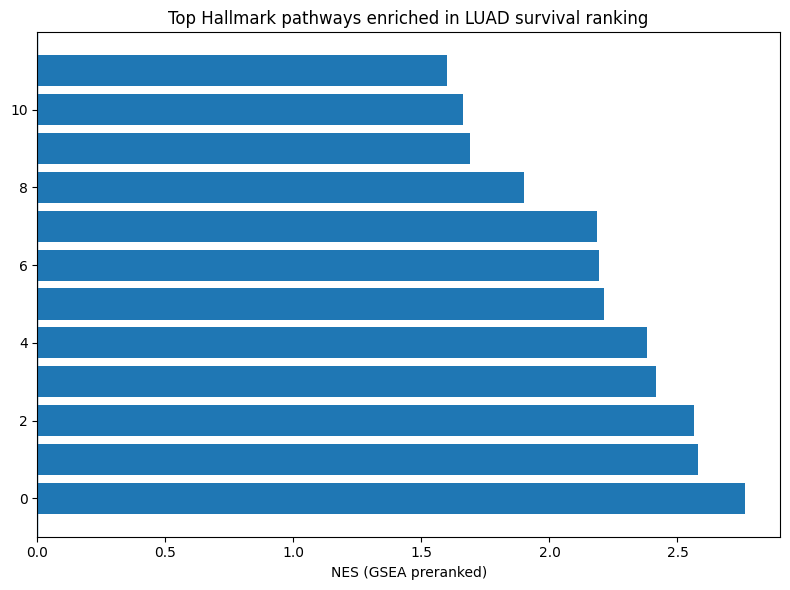

In [51]:
import matplotlib.pyplot as plt

top = gsea_res.head(12).copy()
top = top.iloc[::-1]

plt.figure(figsize=(8,6))
plt.barh(top.index, top["NES"])
plt.axvline(0, linewidth=1)
plt.xlabel("NES (GSEA preranked)")
plt.title("Top Hallmark pathways enriched in LUAD survival ranking")
plt.tight_layout()
plt.show()


In [52]:
# Convertir firma a símbolos usando el mismo mapa
sig_ens = [strip_ensembl_version(g) for g in signature_genes]
sig_sym = [ens2sym.get(g, None) for g in sig_ens]
sig_sym = [s for s in sig_sym if s is not None]

print("Firma original:", len(signature_genes))
print("Firma mapeada a símbolos:", len(sig_sym))
print(sig_sym)

ora = gp.enrichr(
    gene_list=sig_sym,
    gene_sets=["MSigDB_Hallmark_2020", "GO_Biological_Process_2021", "KEGG_2021_Human"],
    organism="Human",
    outdir=None
)

for lib in ora.results["Gene_set"].unique():
    print("\n===", lib, "===")
    display(
        ora.results[ora.results["Gene_set"] == lib]
        .sort_values("Adjusted P-value")
        .head(10)[["Term", "Adjusted P-value", "Overlap", "Genes"]]
    )

Firma original: 15
Firma mapeada a símbolos: 15
['ANKRD65', 'CXCL17', 'LOXL2', 'KRT6A', 'FLNC', 'IRX5', 'IRX3', 'LINC01116', 'DKK1', 'MS4A1', 'BEX5', 'CD79A', 'BCAN-AS1', 'DNALI1', 'KRT81']

=== MSigDB_Hallmark_2020 ===


,Term,Adjusted P-value,Overlap,Genes
0,Primary immunodeficiency,0.233206,1/38,CD79A
1,Pathways of neurodegeneration,0.233206,2/475,DKK1;DNALI1
2,B cell receptor signaling pathway,0.233206,1/81,CD79A
3,Hematopoietic cell lineage,0.233206,1/99,MS4A1
4,Wnt signaling pathway,0.243788,1/166,DKK1
5,Focal adhesion,0.243788,1/201,FLNC
6,Proteoglycans in cancer,0.243788,1/205,FLNC
7,Salmonella infection,0.243788,1/249,FLNC
8,MAPK signaling pathway,0.243788,1/294,FLNC
9,Cytokine-cytokine receptor interaction,0.243788,1/295,CXCL17



=== GO_Biological_Process_2021 ===


,Term,Adjusted P-value,Overlap,Genes
13,Primary immunodeficiency,0.233206,1/38,CD79A
14,Pathways of neurodegeneration,0.233206,2/475,DKK1;DNALI1
15,B cell receptor signaling pathway,0.233206,1/81,CD79A
16,Hematopoietic cell lineage,0.233206,1/99,MS4A1
17,Wnt signaling pathway,0.243788,1/166,DKK1
18,Focal adhesion,0.243788,1/201,FLNC
19,Proteoglycans in cancer,0.243788,1/205,FLNC
20,Salmonella infection,0.243788,1/249,FLNC
21,MAPK signaling pathway,0.243788,1/294,FLNC
22,Cytokine-cytokine receptor interaction,0.243788,1/295,CXCL17



=== KEGG_2021_Human ===


,Term,Adjusted P-value,Overlap,Genes
26,Primary immunodeficiency,0.233206,1/38,CD79A
27,Pathways of neurodegeneration,0.233206,2/475,DKK1;DNALI1
28,B cell receptor signaling pathway,0.233206,1/81,CD79A
29,Hematopoietic cell lineage,0.233206,1/99,MS4A1
30,Wnt signaling pathway,0.243788,1/166,DKK1
31,Focal adhesion,0.243788,1/201,FLNC
32,Proteoglycans in cancer,0.243788,1/205,FLNC
33,Salmonella infection,0.243788,1/249,FLNC
34,MAPK signaling pathway,0.243788,1/294,FLNC
35,Cytokine-cytokine receptor interaction,0.243788,1/295,CXCL17


In [53]:
# Tomamos Hallmark del prerank como "take-home message"
top_tbl = (
    gsea_res
    .reset_index()
    .rename(columns={"index": "Pathway"})
    [["Pathway", "NES", "FDR q-val", "Lead_genes"]]
    .head(8)
)

display(top_tbl)

,Pathway,NES,FDR q-val,Lead_genes
0,0,2.762198,0.0,CCNA2;CDKN3;TPX2;NEK2;KIF4A;CENPA;BIRC5;AURKB;...
1,1,2.579562,0.0,DLGAP5;CDKN3;RRM2;MELK;KIF4A;TK1;BIRC5;CCNE1;A...
2,2,2.564569,0.0,LOXL2;DKK1;SCG2;SPOCK1;PLOD2;PTHLH;COL5A2;GJA1...
3,7,2.18402,0.001264,STC1;IER3;ANGPTL4;PLOD2;DDIT4;CENPA;PKP2;STC2;...
4,6,2.195111,0.001444,ID1;COL5A2;GJA1;SERPINE1;COL11A1;COL1A2;COL3A1...
5,5,2.214791,0.001685,STC1;RRM2;PLOD2;DDIT4;SLC2A1;EGLN3;AK4;TXNRD1;...
6,4,2.381035,0.002022,IER3;FOSL1;KYNU;KLF4;SERPINE1;CCL20;NR4A2;GEM;...
7,3,2.415857,0.002527,AKAP12;STC1;IER3;ANGPTL4;INHA;DDIT4;HOXB9;SLC2...


In [56]:
gsea_res.head(10)

,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes
0,prerank,G2-M Checkpoint,0.877032,2.762198,0.0,0.0,0.0,18/22,9.50%,CCNA2;CDKN3;TPX2;NEK2;KIF4A;CENPA;BIRC5;AURKB;...
1,prerank,E2F Targets,0.877114,2.579562,0.0,0.0,0.0,15/19,8.09%,DLGAP5;CDKN3;RRM2;MELK;KIF4A;TK1;BIRC5;CCNE1;A...
2,prerank,Epithelial Mesenchymal Transition,0.67356,2.564569,0.0,0.0,0.0,44/74,20.56%,LOXL2;DKK1;SCG2;SPOCK1;PLOD2;PTHLH;COL5A2;GJA1...
7,prerank,Glycolysis,0.629152,2.18402,0.0,0.001264,0.005,20/33,20.30%,STC1;IER3;ANGPTL4;PLOD2;DDIT4;CENPA;PKP2;STC2;...
6,prerank,UV Response Dn,0.683637,2.195111,0.0,0.001444,0.005,12/23,14.98%,ID1;COL5A2;GJA1;SERPINE1;COL11A1;COL1A2;COL3A1...
5,prerank,mTORC1 Signaling,0.754813,2.214791,0.0,0.001685,0.005,18/19,23.90%,STC1;RRM2;PLOD2;DDIT4;SLC2A1;EGLN3;AK4;TXNRD1;...
4,prerank,TNF-alpha Signaling via NF-kB,0.633955,2.381035,0.0,0.002022,0.005,30/51,21.29%,IER3;FOSL1;KYNU;KLF4;SERPINE1;CCL20;NR4A2;GEM;...
3,prerank,Hypoxia,0.629632,2.415857,0.0,0.002527,0.005,28/45,20.93%,AKAP12;STC1;IER3;ANGPTL4;INHA;DDIT4;HOXB9;SLC2...
8,prerank,Apoptosis,0.622509,1.898741,0.0,0.00337,0.015,15/20,30.58%,IER3;EREG;TOP2A;PMAIP1;CAV1;BIRC3;IL6;BMP2;PLA...
9,prerank,KRAS Signaling Up,0.450364,1.691428,0.0,0.017186,0.075,29/61,22.81%,AKAP12;ANGPTL4;SCG5;EREG;CPE;KLF4;CCL20;ANXA10...


In [58]:
sig_df[["gene", "HR", "p"]]

,gene,HR,p
0,ENSG00000235098.8,0.283595,0.000009
1,ENSG00000189377.9,0.297783,0.000047
2,ENSG00000134013.16,4.739155,0.000074
3,ENSG00000205420.11,1.698760,0.000094
4,ENSG00000128591.16,2.620428,0.000114
5,ENSG00000176842.15,0.452229,0.000147
6,ENSG00000177508.12,0.303872,0.000197
7,ENSG00000163364.10,2.138199,0.000281
8,ENSG00000107984.10,1.726875,0.000297
9,ENSG00000156738.18,0.505216,0.000381


**🔬 GSEA preranked: la señal dominante es proliferativa y mesenquimal**

El análisis GSEA sobre el ranking transcriptómico asociado a supervivencia muestra un patrón muy claro. Las vías más enriquecidas corresponden a procesos centrales de progresión tumoral, con valores de NES elevados y FDR prácticamente nulos.

Las señales más fuertes están dominadas por G2/M checkpoint y E2F targets, lo que indica que los pacientes con peor pronóstico presentan una activación marcada de programas de proliferación celular y control del ciclo celular. Este hallazgo es consistente con una mayor fracción de células en división activa y con tumores biológicamente más agresivos.

En paralelo, aparece de forma robusta la transición epitelio-mesenquimal (EMT), una firma clásica asociada a invasión, plasticidad celular y potencial metastásico. La coexistencia de proliferación elevada y EMT sugiere que el transcriptoma está capturando no solo velocidad de crecimiento tumoral, sino también capacidad de diseminación.

Otras vías relevantes refuerzan este eje biológico: hipoxia, glucólisis y mTORC1 signaling apuntan a una reprogramación metabólica adaptativa, típica de tumores que crecen en microambientes hostiles. Finalmente, la activación de TNF-α / NF-κB introduce un componente inflamatorio y de señalización de estrés, frecuentemente vinculado a progresión tumoral y resistencia terapéutica.

En conjunto, el GSEA indica que el riesgo transcriptómico no es una señal abstracta, sino la manifestación coordinada de proliferación, plasticidad celular y adaptación metabólica, todos rasgos bien establecidos de mal pronóstico en LUAD.

**🧬 Firma transcriptómica: genes con roles funcionales coherentes**

La firma final de 15 genes es heterogénea, pero funcionalmente interpretable. Incluye genes asociados a:

* Remodelado de matriz extracelular e invasión (LOXL2, FLNC)

* Señalización Wnt / diferenciación (DKK1)

* Identidad epitelial y queratinización (KRT6A, KRT81)

* Componentes inmunes y linfocitarios (MS4A1, CD79A, CXCL17)

* Factores de desarrollo y regulación transcripcional (IRX3, IRX5)

El hecho de que algunos genes presenten HR > 1 y otros HR < 1 es esperable y deseable: la firma no representa un único proceso, sino un balance entre programas biológicos que favorecen o atenúan el riesgo. El puntaje transcriptómico emerge justamente de esa combinación.

Es importante notar que el análisis ORA sobre la firma individual no arroja enriquecimientos significativos tras corrección múltiple. Esto no es una debilidad, sino una consecuencia directa del tamaño reducido de la firma. La coherencia biológica aparece con claridad cuando se analiza el transcriptoma completo mediante GSEA, no cuando se evalúan 15 genes de forma aislada.



**📊 Coherencia global**

Hay una alineación muy sólida entre:

* GSEA (señal global del transcriptoma),

* firma transcriptómica (resumen parsimonioso),

* Kaplan–Meier en test,

* y modelo de Cox multivariado.

Todo apunta a que la firma está capturando un eje biológico real de agresividad tumoral, y no una asociación espuria.